**Libraries**

In [ ]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

First, we should call data sets from splitting section.

In [2]:
%store -r X_train
X_train = X_train

%store -r y_train
y_train = y_train

%store -r X_val
X_val = X_val

%store -r y_val
y_val = y_val

%store -r X_test
X_test = X_test

%store -r y_test
y_test = y_test

based on each model, we define specific pipeline and build and train model.

In [3]:
def evaluate_model(X_train, y_train, X_val, y_val, model):
    kf = KFold(n_splits=5, shuffle=True, random_state=42)

    cross_val_r2 = cross_val_score(model, X_train, y_train, cv=kf, scoring='r2')
    cross_val_rmse = cross_val_score(
        model, X_train, y_train,
        cv=kf,
        scoring='neg_root_mean_squared_error'
    )

    print(f"Training CV R²: {cross_val_r2.mean():.4f}, Training CV RMSE: {-cross_val_rmse.mean():.4f}")

    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_val_pred = model.predict(X_val)

    r2_train = r2_score(y_train, y_train_pred)
    rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))

    r2_val = r2_score(y_val, y_val_pred)
    rmse_val = np.sqrt(mean_squared_error(y_val, y_val_pred))

    print(f"Training R²: {r2_train:.4f}, Training RMSE: {rmse_train:.4f}")
    print(f"Validation R²: {r2_val:.4f}, Validation RMSE: {rmse_val:.4f}")

## **Model Training**

**Linear Regression**

In [4]:
model =  Pipeline([
    ('scaler', StandardScaler()), #this algorithm needs scalling
     ('lin_reg', LinearRegression())
])
evaluate_model(X_train, y_train, X_val, y_val, model)

Training CV R²: 0.9990, Training CV RMSE: 96.3372
Training R²: 0.9990, Training RMSE: 98.4016
Validation R²: 0.9993, Validation RMSE: 85.1665


the model is not `Underfit`(both  Cross Validation and Validation are high) and `Overfit`(CV amd validation are close to each other)

**Decision Tree Regressor**

In [5]:
model = Pipeline([
    ("DecisionTree_reg", DecisionTreeRegressor())
])

evaluate_model(X_train, y_train, X_val, y_val, model)

Training CV R²: 0.8816, Training CV RMSE: 1072.3863
Training R²: 1.0000, Training RMSE: 0.0000
Validation R²: 0.8973, Validation RMSE: 1011.1136


This model is overfit(CV train and train have gap). But, since the gap between CV train and Validation is small, that overfitting is not severe.

**Random Forest Regressor**

In [6]:
model = Pipeline([
    ('RandomForest_reg', RandomForestRegressor())
])

evaluate_model(X_train, y_train, X_val, y_val, model)

Training CV R²: 0.9547, Training CV RMSE: 663.7273
Training R²: 0.9942, Training RMSE: 239.5997
Validation R²: 0.9629, Validation RMSE: 607.4074


**Support Vector Machine**

In [7]:
model = Pipeline([
    ('scaler', StandardScaler()), #this algorithm needs scalling
    ('svr', SVR(kernel='rbf'))
])

evaluate_model(X_train, y_train, X_val, y_val, model)

Training CV R²: 0.0538, Training CV RMSE: 3046.4456
Training R²: 0.0696, Training RMSE: 3022.4816
Validation R²: 0.0683, Validation RMSE: 3045.1092


**Model Selection**

Based on the result of default model training, the best model is `Linear Reggression` with R2 0.9993, RMSE $85

In [8]:
best_model = LinearRegression()
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cross_val_r2 = cross_val_score(model, X_train, y_train, cv=kf, scoring='r2')
cross_val_rmse = cross_val_score(
    model, X_train, y_train,
    cv=kf,
     scoring='neg_root_mean_squared_error'
 )

print(f"Training CV R²: {cross_val_r2.mean():.4f}, Training CV RMSE: {-cross_val_rmse.mean():.4f}")

best_model.fit(X_train, y_train)

y_train_pred = best_model.predict(X_train)
y_val_pred = best_model.predict(X_val)

r2_train = r2_score(y_train, y_train_pred)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))

r2_val = r2_score(y_val, y_val_pred)
rmse_val = np.sqrt(mean_squared_error(y_val, y_val_pred))

print(f"Training R²: {r2_train:.4f}, Training RMSE: {rmse_train:.4f}")
print(f"Validation R²: {r2_val:.4f}, Validation RMSE: {rmse_val:.4f}")

Training CV R²: 0.0538, Training CV RMSE: 3046.4456
Training R²: 0.9990, Training RMSE: 98.4016
Validation R²: 0.9993, Validation RMSE: 85.1665


**Hyper-Parameter Tuning**

we'll try to tune the model and improve its perfomance.

In [9]:
param_grid = {
    'fit_intercept': [True, False],
    'positive': [True, False]
}

grid_search = GridSearchCV(
    estimator=best_model,
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)

print("Best parameters found: ", grid_search.best_params_)
print("Best CV RMSE: ", -grid_search.best_score_)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters found:  {'fit_intercept': True, 'positive': False}
Best CV RMSE:  97.2521326282186


**tuned Linear Regression model**

In [10]:
best_model_tuned = grid_search.best_estimator_

In [11]:
best_model_tuned = grid_search.best_estimator_

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cross_val_r2 = cross_val_score(
    best_model_tuned,
    X_train,
    y_train,
    cv=kf,
    scoring='r2'
)

cross_val_rmse = -cross_val_score(
    best_model_tuned,
    X_train,
    y_train,
    cv=kf,
    scoring='neg_root_mean_squared_error'
)

print(
    f"Training CV R²: {cross_val_r2.mean():.4f}, "
    f"Training CV RMSE: {cross_val_rmse.mean():.4f}"
)

best_model_tuned.fit(X_train, y_train)

y_train_pred = best_model_tuned.predict(X_train)
y_val_pred = best_model_tuned.predict(X_val)

r2_train = r2_score(y_train, y_train_pred)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))

r2_val = r2_score(y_val, y_val_pred)
rmse_val = np.sqrt(mean_squared_error(y_val, y_val_pred))

print(f"Training R²: {r2_train:.4f}, Training RMSE: {rmse_train:.4f}")
print(f"Validation R²: {r2_val:.4f}, Validation RMSE: {rmse_val:.4f}")

Training CV R²: 0.9990, Training CV RMSE: 96.3372
Training R²: 0.9990, Training RMSE: 98.4016
Validation R²: 0.9993, Validation RMSE: 85.1665


The optimal parameters were fit_intercept=True and positive=False, which correspond to the default Linear Regression configuration. Therefore, tuning did not improve the model's performance. The final model achieved a validation R² of `0.9993` and validation RMSE of `85.1665.`

In [17]:
final_model = best_model

**Final Evaluation of Model**

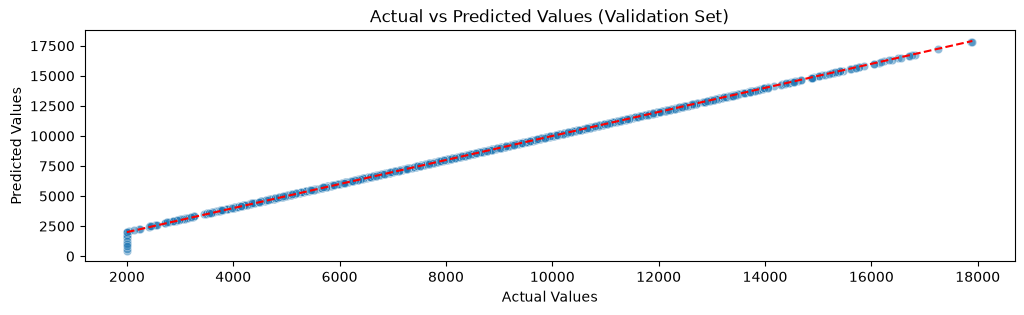

In [18]:
#Scatter plot of actual vs predicted values for the validation set
plt.figure(figsize=(12, 3))

sns.scatterplot(x=y_val, y=y_val_pred, alpha=0.5)

plt.plot([min(y_val), max(y_val)], [min(y_val), max(y_val)], '--', color='red')
plt.title('Actual vs Predicted Values (Validation Set)')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.show()

In [19]:
best_model.fit(X_train, y_train)

y_val_pred = best_model.predict(X_val)

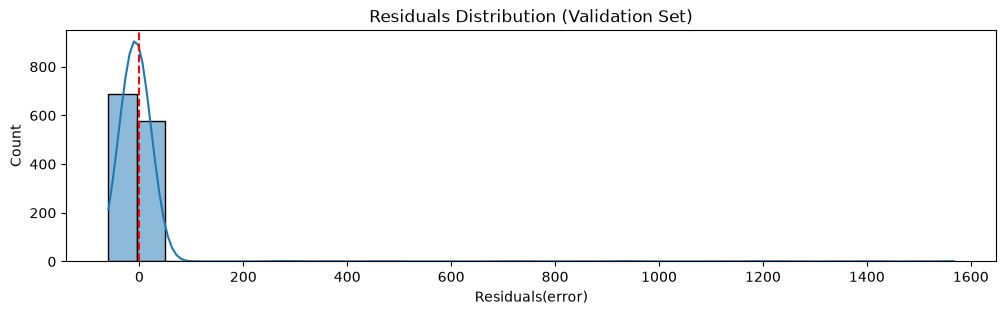

In [20]:
#Residual plot for the validation set
residuals = y_val - y_val_pred

plt.figure(figsize=(12, 3))
sns.histplot(residuals, bins=30, kde=True)
plt.axvline(0, color='red', linestyle='dashed')
plt.xlabel('Residuals(error)')
plt.title('Residuals Distribution (Validation Set)')
plt.show()

**Apply the Model on Test Data**

Here, we are happy with the model of the project we can predict the price on test data. But before prediction, we need to encode categorical features.

In [21]:
with open('../../models/Brand_Encoder.pkl', 'rb') as f:
    brand_encoder = pickle.load(f)  #Brand

with open('../../models/Model_Encoder.pkl', 'rb') as f:
    model_encoder = pickle.load(f)  #Model

with open('../../models/OneHot_Encoder.pkl', 'rb') as f:
    onehot_encoder = pickle.load(f)  #Fuel + Transmission

In the next step, we should encode categorical features.

In [22]:
# Encoding Brand and Model
X_test['Encoded_Brand'] = X_test['Brand'].map(brand_encoder)
X_test['Encoded_Model'] = X_test['Model'].map(model_encoder)

X_test['Encoded_Brand'].fillna(
    X_test['Encoded_Brand'].mean(), inplace=True
)

X_test['Encoded_Model'].fillna(
    X_test['Encoded_Model'].mean(), inplace=True
)

X_test.drop(['Brand', 'Model'], axis=1, inplace=True)


# Encoding Fuel and Transmission
categorical_cols = ['Fuel', 'Transmission']

encoded_array = onehot_encoder.transform(
    X_test[categorical_cols]
)

encoded_df_test = pd.DataFrame(
    encoded_array,
    columns=onehot_encoder.get_feature_names_out(categorical_cols)
)

X_test = X_test.drop(
    columns=categorical_cols
).reset_index(drop=True)

X_test = pd.concat([X_test, encoded_df_test], axis=1)

Now, we can predict the test data.

In [23]:
y_test_pred = final_model.predict(X_test)

r2_test = r2_score(y_test, y_test_pred)
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

print(f"Test R²: {r2_test:.4f}, Test RMSE: {rmse_test:.4f}")

Test R²: 0.9996, Test RMSE: 63.3607


The result shows model is good genralized and there is no overfitting/underfitting.

**Checkpoint**

In [24]:
pickle.dump(final_model, open('../../models/Model.pkl', 'wb'))